Net(
  (fc1): Linear(in_features=1, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=1, bias=True)
)
[Parameter containing:
tensor([[ 0.3777],
        [-0.1044],
        [ 0.4919],
        [-0.1101],
        [ 0.4818],
        [ 0.9199],
        [-0.5703],
        [-0.0300],
        [ 0.3214],
        [ 0.6716],
        [-0.0382],
        [ 0.0648],
        [-0.2025],
        [ 0.4591],
        [-0.2250],
        [ 0.3939],
        [ 0.0342],
        [ 0.9460],
        [ 0.8839],
        [ 0.8684],
        [-0.7944],
        [ 0.2818],
        [-0.6340],
        [-0.7077],
        [ 0.3175],
        [ 0.2896],
        [-0.2811],
        [ 0.0772],
        [ 0.2698],
        [ 0.4795],
        [-0.1884],
        [ 0.7584],
        [-0.8565],
        [ 0.2147],
        [-0.0526],
        [ 0.8160],
        [-0.2901],
        [-0.7196],
        [-0.5193],
        [-0.1136],
        [ 0.4699],
        [

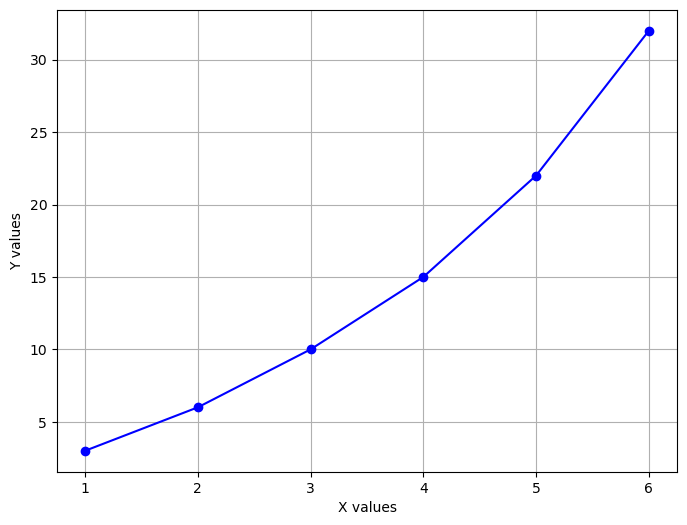

In [281]:
### Training with fancier version ###

import torch
import torch.nn as nn
import torch.nn.functional as F

import torch.optim as optim
import matplotlib.pyplot as plt

class Net(nn.Module): ## nn.Module class is used
    def __init__(self):
        super(Net, self).__init__()
        self.fc1 = nn.Linear(1,128)  # in dim, out dim
        self.fc2 = nn.Linear(128,128)  # in dim, out dim
        self.fc3 = nn.Linear(128,1)  # in dim, out dim
        
    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.sigmoid(self.fc2(x))
        x = F.relu(self.fc3(x))
        return x

net = Net()

print(net)
print(list(net.parameters())) # parameters are randomized


#def criterion(out, label):
#    return (label - out)**2
criterion = nn.MSELoss()


optimizer = optim.SGD(net.parameters(), lr=0.001)
#optimizer = optim.Adam(net.parameters(), lr=0.1)


data = [(1.0,3.0), (2.0,6.0), (3.0,10.0), (4.0,15.0), (5.0,22.0), (6.0,32.0)]

# Split data into x and y
x_values, y_values = zip(*data)

# Plotting
plt.figure(figsize=(8, 6))
plt.plot(x_values, y_values, marker='o', linestyle='-', color='b')
plt.xlabel('X values')
plt.ylabel('Y values')
plt.grid(True)
plt.show()

In [282]:
for epoch in range(1000): # 0 - 19
    for i, current_data in enumerate(data):
        X, Y = current_data
        X, Y = torch.FloatTensor([X]), torch.FloatTensor([Y])
        optimizer.zero_grad()   
        outputs = net(X)
        loss = criterion(outputs, Y)
        loss.backward()
        optimizer.step()    ## This line is equivalent to "W = W - lr* W.grad"
    print("Epoch {} - loss: {}".format(epoch, loss))


### Test the trained network ###      
y_net = []      
for i, current_data in enumerate(data):
    X, Y = current_data
    X, Y = torch.FloatTensor([X]), torch.FloatTensor([Y])  
    out = net(torch.FloatTensor(X))  
    y_net.append(out.item())
    print("when x = {}, y = {}".format(X, out))
    

Epoch 0 - loss: 743.7461547851562
Epoch 1 - loss: 427.3701171875
Epoch 2 - loss: 282.65032958984375
Epoch 3 - loss: 228.6691131591797
Epoch 4 - loss: 207.30313110351562
Epoch 5 - loss: 196.96868896484375
Epoch 6 - loss: 190.36734008789062
Epoch 7 - loss: 185.0866241455078
Epoch 8 - loss: 180.33853149414062
Epoch 9 - loss: 175.85330200195312
Epoch 10 - loss: 171.50119018554688
Epoch 11 - loss: 167.22372436523438
Epoch 12 - loss: 162.96424865722656
Epoch 13 - loss: 158.67831420898438
Epoch 14 - loss: 154.35269165039062
Epoch 15 - loss: 150.020263671875
Epoch 16 - loss: 145.64239501953125
Epoch 17 - loss: 141.2289276123047
Epoch 18 - loss: 136.76788330078125
Epoch 19 - loss: 132.35069274902344
Epoch 20 - loss: 127.93804931640625
Epoch 21 - loss: 123.51634216308594
Epoch 22 - loss: 119.04195404052734
Epoch 23 - loss: 114.5372085571289
Epoch 24 - loss: 110.01836395263672
Epoch 25 - loss: 105.52838897705078
Epoch 26 - loss: 101.09996032714844
Epoch 27 - loss: 96.71085357666016
Epoch 28 - los

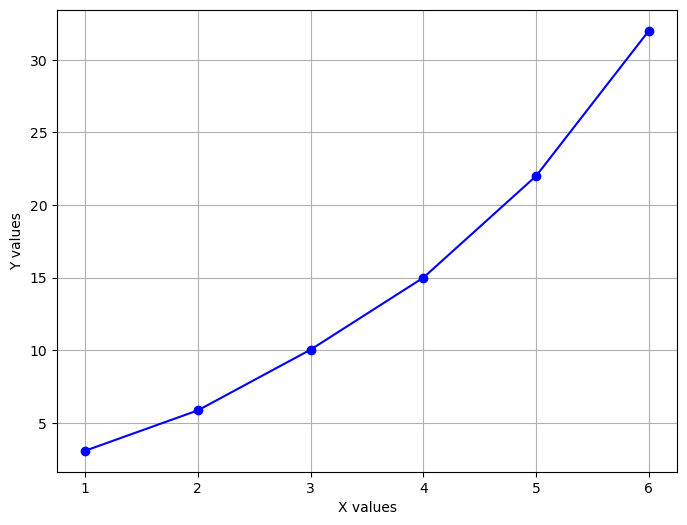

Final Epoch 999 - loss: 4.558969521895051e-07
Final loss < 1e-5: True


In [283]:
plt.figure(figsize=(8, 6))
plt.plot(x_values, y_net, marker='o', linestyle='-', color='b')
plt.xlabel('X values')
plt.ylabel('Y values')
plt.grid(True)
plt.show()

print("Final Epoch {} - loss: {}".format(epoch, loss))
print("Final loss < 1e-5: {}".format(loss < 1e-5))

In [284]:
X

tensor([6.])

In [285]:
for epoch in range(20):
    print(epoch)

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19


In [286]:
W = torch.tensor([1.0], requires_grad=True)
W = W*2
label = 1.0
loss = W*5 - label 
loss.backward()
W.grad

/tmp/ipykernel_850/353321738.py:6: UserWarning: The .grad attribute of a Tensor that is not a leaf Tensor is being accessed. Its .grad attribute won't be populated during autograd.backward(). If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor. If you access the non-leaf Tensor by mistake, make sure you access the leaf Tensor instead. See github.com/pytorch/pytorch/pull/30531 for more informations. (Triggered internally at aten/src/ATen/core/TensorBody.h:489.)
  W.grad
